# EDA банка вопросов

**Зачем этот анализ.** Банк вопросов сгенерирован LLM и будет меняться, поэтому описывать его ради описания смысла нет.
Анализ ищет свойства, которые влияют на задачу проверки и на сборку оценочного набора:

1. дефекты формата, которые искажают вход проверяющей модели;
2. размер чек-листов — от него зависят объём оценочного набора и баланс классов;
3. однозначность тезисов — от неё зависит, можно ли вообще правильно разметить вердикт «раскрыт частично»;
4. почти-дубликаты — от них зависит разбиение оценочного набора без утечки;
5. длина эталонов — оценка длительности устного ответа и стоимости проверки.

Каждый раздел заканчивается выводом и решением. Итоговая таблица решений — в конце.

In [1]:
import re
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

ROOT = Path.cwd() if (Path.cwd() / "app").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from app.schema import parse_text  # noqa: E402

pd.set_option("display.max_colwidth", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 0. Загрузка

Банк читается тем же парсером, что и приложение (`app.schema.parse_text`), поэтому анализ видит ровно то, что получает
проверяющая модель. Демо-вопросы (`questions/demo/`) исключены. При повторе `id` побеждает более свежий файл — так же,
как при импорте в приложении.

In [2]:
bank = {}
for p in sorted((ROOT / "questions").rglob("*.yaml"), key=lambda p: (p.stat().st_mtime, str(p))):
    if p.name.startswith(("_", ".")) or "demo" in p.parts:
        continue
    res = parse_text(p.read_text(encoding="utf-8"), p.name)
    assert not res.errors, res.errors
    for q in res.questions:
        bank[q.id] = q

questions = list(bank.values())
open_qs = [q for q in questions if q.type == "open"]
print(f"Всего вопросов: {len(questions)}, открытых с чек-листом: {len(open_qs)}")

Всего вопросов: 366, открытых с чек-листом: 71


## 1. Состав банка

Только чтобы понимать, из чего собирается оценочный набор. Распределения по сложности и темам не анализируются:
их тоже проставила модель, и решения от них не зависят.

In [3]:
types = pd.Series(Counter(q.type for q in questions)).sort_values(ascending=False)
topics = pd.Series(Counter(q.topic.split("/")[0] for q in open_qs)).sort_values(ascending=False)
display(types.rename("вопросов").to_frame().T)
display(topics.rename("открытых вопросов").to_frame().T)

,mcq,open,card,multi,code
вопросов,192,71,63,37,3


,stats,ml,math,dl,python
открытых вопросов,29,25,12,3,2


**Вывод.** Моделью проверяются только открытые вопросы: только у них есть чек-лист. Карточки (`card`) чек-листа
не имеют и в оценочный набор не входят. Основа набора — 71 открытый вопрос; темы в основном статистика и ML.

## 2. Дефекты формата

Тезис чек-листа должен быть строкой. Ищем значения, которые выглядят как текст словаря Python.

In [4]:
defects = [
    (q.id, i, t) for q in open_qs for i, t in enumerate(q.rubric, 1) if re.fullmatch(r"\{'.*'\}", t.strip(), re.S)
]
pd.DataFrame(defects, columns=["вопрос", "тезис №", "текст тезиса"])

,вопрос,тезис №,текст тезиса
0,dlo-warm-007,4,{'Назвал специфику трансформеров': 'насыщение softmax в attention или чувствительность глубоких residual-стеков'}
1,dlo-choice-013,2,{'Назвал сильные стороны Adam/AdamW': 'скорость сходимости и устойчивость к выбору LR'}


**Вывод.** Два тезиса хранятся как текст словаря, и именно так их видит проверяющая модель.

**Причина.** В ответе чата-автора пункт списка содержал «текст: текст» без кавычек, YAML прочитал его как словарь,
а валидатор `_list_of_str` в `app/schema.py` молча превратил словарь в строку через `str()`. При импорте это сохранилось
в файл банка.

**Решение.** Исправить два тезиса; валидатор должен отклонять элементы списка, которые не являются строками,
чтобы такой дефект не появлялся при следующих пополнениях банка.

## 3. Размер чек-листов

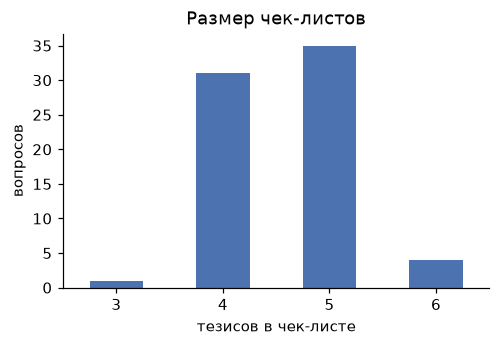

Всего тезисов: 326; доля чек-листов из 4–5 тезисов: 93%


In [5]:
sizes = pd.Series([len(q.rubric) for q in open_qs])
n_theses = int(sizes.sum())
ax = sizes.value_counts().sort_index().plot.bar(color="#4c72b0", rot=0, figsize=(5, 3))
ax.set_xlabel("тезисов в чек-листе")
ax.set_ylabel("вопросов")
ax.set_title("Размер чек-листов")
plt.show()
print(f"Всего тезисов: {n_theses}; доля чек-листов из 4–5 тезисов: {sizes.between(4, 5).mean():.0%}")

**Вывод.** Почти все чек-листы содержат 4–5 тезисов, всего 326 тезисов. Для оценочного набора это значит:
при 6 сценариях на вопрос получится около 430 ответов и около 1 950 решений на уровне тезисов. Этого достаточно, чтобы
считать macro-F1 по трём классам с приемлемой точностью; баланс классов задаётся сценариями, а не природой данных.

## 4. Однозначность тезисов

Вердикт «раскрыт частично» осмыслен, только если понятно, что такое «полностью». Это нарушается в двух случаях:

- **составной тезис** — два обязательных действия в одном пункте: «назвал X **и** объяснил Y». Если кандидат назвал X,
  но не объяснил Y, неясно, частично это или не раскрыто;
- **перечисление без меры** — «предложил решения: A, B, C, D». Неясно, сколько элементов нужно назвать.

**Как определяем.** Почти каждый тезис начинается с глагола действия («назвал», «объяснил»…). Словарь таких глаголов
берём из самих данных — по первым словам тезисов. Тезис составной, если в нём два и более таких глагола, кроме случая,
когда они разделены «или» (это варианты, достаточно одного). Перечисление — список из трёх и более элементов после
двоеточия или в скобках; мерой считаются слова вроде «хотя бы», «все», «два».

In [6]:
WORD = r"[A-Za-zА-Яа-яЁё]+"
items = [(q.id, i, t) for q in open_qs for i, t in enumerate(q.rubric, 1)]
first_words = Counter(re.match(WORD, t).group(0).lower() for _, _, t in items if re.match(WORD, t))
VERBS = {w for w in first_words if w not in {"правильно", "сначала", "первой"}}  # наречия, а не действия
QUANT = re.compile(r"\b(хотя бы|как минимум|минимум|все|оба|обе|один из|одну из|два|две|три|четыре)\b", re.I)


def n_actions(text):
    # действия, разделённые «или», — альтернативы, а не два обязательных шага
    return max(sum(w in VERBS for w in re.findall(WORD, part.lower())) for part in re.split(r"\s+или\s+", text))


def enum_size(text):
    segments = ([text.split(":", 1)[1]] if ":" in text else []) + re.findall(r"\(([^)]*)\)", text)
    return max((1 + len(re.findall(r",| и | или |/", s)) for s in segments), default=0)


def category(text):
    if n_actions(text) >= 2:
        return "составной"
    if enum_size(text) >= 3:
        return "перечисление с мерой" if QUANT.search(text) else "перечисление без меры"
    return "атомарный"


theses = pd.DataFrame(items, columns=["вопрос", "№", "тезис"])
theses["категория"] = theses["тезис"].map(category)
flagged = theses[theses["категория"].isin(["составной", "перечисление без меры"])]
flagged

,вопрос,№,тезис,категория
2,la-mcoll-005,3,"Назвал Ridge и объяснил, что $\lambda I$ делает матрицу обратимой",составной
3,la-mcoll-005,4,"Предложил альтернативы: удаление признака, PCA, решение через SVD или QR",перечисление без меры
13,mlm-pr-003,2,"Привёл пример, где важнее recall, и объяснил почему",составной
14,mlm-pr-003,3,"Привёл пример, где важнее precision, и объяснил почему",составной
43,mlv-leak-011,4,"Проверил методологию: предобработка до split, дубликаты, перемешивание временных данных",перечисление без меры
46,mlv-diag-015,2,"Описал недообучение как высокие и близкие ошибки, предложил усложнение модели",составной
47,mlv-diag-015,3,"Описал переобучение как разрыв между train и validation, предложил регуляризацию или больше данных",составной
59,mlr-scale-011,2,"Предложил относительную метрику: MAPE, WAPE или логарифмирование таргета",перечисление без меры
74,np-debug-014,3,"Назвал типичные причины: транспонирование, забытый reshape, неверная ось агрегирования",перечисление без меры
92,mc-chain-005,4,"Предложил решения: ReLU, нормализация, residual-связи, клиппинг",перечисление без меры


**Ручная проверка.** Все отмеченные тезисы просмотрены вручную (таблица выше). Ложными признаны три — правило
их не различает:

,вопрос,№,почему ложное
0,mllin-coef-005,2,"одно действие с оговоркой («не сказал…»), а не два действия"
1,mlr-scale-011,2,"«относительную метрику: A, B или C» — достаточно одного варианта"
2,stcup-risk-015,2,"не перечисление, а определение через двоеточие"


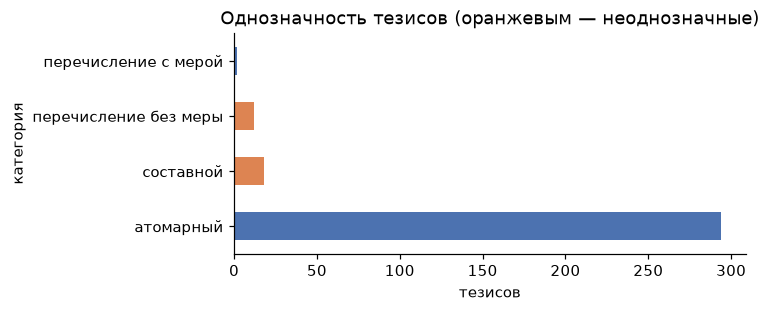

Неоднозначных тезисов: 30 из 326 (9%); вопросов хотя бы с одним: 25 из 71 (35%)

In [7]:
MANUAL_FALSE = {
    ("mllin-coef-005", 2): "одно действие с оговоркой («не сказал…»), а не два действия",
    ("mlr-scale-011", 2): "«относительную метрику: A, B или C» — достаточно одного варианта",
    ("stcup-risk-015", 2): "не перечисление, а определение через двоеточие",
}
display(pd.DataFrame([(k[0], k[1], v) for k, v in MANUAL_FALSE.items()], columns=["вопрос", "№", "почему ложное"]))

is_false = theses.apply(lambda r: (r["вопрос"], r["№"]) in MANUAL_FALSE, axis=1)
theses.loc[is_false, "категория"] = "атомарный"  # ложные срабатывания после ручной проверки
AMBIGUOUS = ["составной", "перечисление без меры"]
theses["неоднозначный"] = theses["категория"].isin(AMBIGUOUS)

counts = theses["категория"].value_counts()
ax = counts.plot.barh(color=["#dd8452" if c in AMBIGUOUS else "#4c72b0" for c in counts.index], figsize=(6, 2.6))
ax.set_xlabel("тезисов")
ax.set_title("Однозначность тезисов (оранжевым — неоднозначные)")
plt.show()

amb = theses["неоднозначный"]
q_amb = theses.groupby("вопрос")["неоднозначный"].any()
print(
    f"Неоднозначных тезисов: {amb.sum()} из {len(theses)} ({amb.mean():.0%}); "
    f"вопросов хотя бы с одним: {q_amb.sum()} из {len(q_amb)} ({q_amb.mean():.0%})"
)

**Вывод.** Около одного тезиса из десяти неоднозначен, и такие тезисы есть примерно в трети вопросов. Это прямо влияет
на ML-задачу: для них правильный вердикт «раскрыт частично» не определён, поэтому разметка будет шумной, а модель
будет наказываться за ответы, которые эксперт мог бы засчитать.

**Решения.**

1. Перед сборкой оценочного набора переписать неоднозначные тезисы: составной разбить на два, в перечисление добавить
   меру («хотя бы два из…»). В банке уже есть пример правильной формы: «Назвал хотя бы две функции потерь…».
2. Добавить правило в промпт генерации вопросов (`docs/PROMPT_FOR_QUESTION_CHAT.md`): «один тезис — одно проверяемое
   действие; для перечислений указывать, сколько элементов достаточно». Так правило действует и на будущие вопросы.

## 5. Почти-дубликаты

Если похожие вопросы попадут и в часть для подбора промптов, и в отложенную часть, качество на отложенной части будет
завышено. Сравниваем вопросы вместе с чек-листами по символьным n-граммам (устойчиво к словоформам).

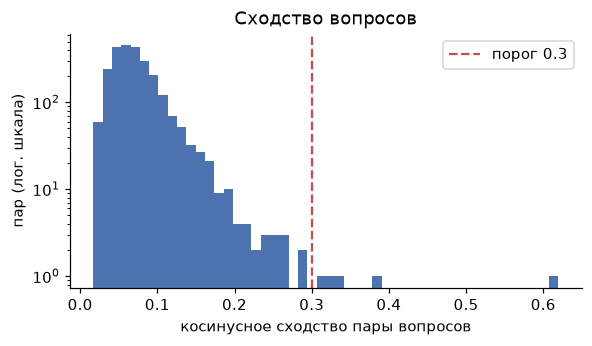

квантили сходства 50/90/99%: [0.067 0.113 0.2  ]


,вопрос A,вопрос B,сходство
0,mlm-loss-013,mc-surr-009,0.62
1,mlv-leak-007,mlv-leak-011,0.38
2,mc-chain-005,mc-vanish-013,0.33
3,mlv-leak-011,mlint-leak-011,0.32
4,mll-choose-007,mll-imb-015,0.32


In [8]:
docs = [q.question + " " + " ".join(q.rubric) for q in open_qs]
X = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True).fit_transform(docs)
S = cosine_similarity(X)
iu = np.triu_indices(len(open_qs), 1)
sims = S[iu]
THRESHOLD = 0.3

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(sims, bins=50, color="#4c72b0")
ax.axvline(THRESHOLD, color="#c44e52", ls="--", label=f"порог {THRESHOLD}")
ax.set_yscale("log")
ax.set_xlabel("косинусное сходство пары вопросов")
ax.set_ylabel("пар (лог. шкала)")
ax.set_title("Сходство вопросов")
ax.legend()
plt.show()
print("квантили сходства 50/90/99%:", np.quantile(sims, [0.5, 0.9, 0.99]).round(3))

pairs = [(open_qs[a].id, open_qs[b].id, S[a, b]) for a, b in zip(*iu, strict=True) if S[a, b] >= THRESHOLD]
pd.DataFrame(sorted(pairs, key=lambda x: -x[2]), columns=["вопрос A", "вопрос B", "сходство"]).round(2)

In [9]:
# группы: связные компоненты графа пар выше порога
parent = {q.id: q.id for q in open_qs}


def find(x):
    while parent[x] != x:
        x = parent[x]
    return x


for a, b, _ in pairs:
    parent[find(a)] = find(b)
groups = Counter(find(q.id) for q in open_qs)
multi = {g: [q.id for q in open_qs if find(q.id) == g] for g, n in groups.items() if n > 1}
for members in multi.values():
    print(" + ".join(members))

mlm-loss-013 + mc-surr-009
mlv-leak-007 + mlv-leak-011 + mlint-leak-011
mc-chain-005 + mc-vanish-013
mll-choose-007 + mll-imb-015


**Вывод.** Типичное сходство вопросов низкое (медиана около 0,07), а пары выше порога 0,3 лежат далеко за 99-м
перцентилем — это явные выбросы. Пара `mlm-loss-013` и `mc-surr-009` (0,62) — по сути один вопрос с совпадающими
тезисами; остальные группы — вопросы об одном явлении (утечка данных, затухание градиентов, выбор функции потерь).

**Решения.**

1. Оценочный набор делить по группам: вопросы одной группы целиком попадают либо в часть для подбора, либо в отложенную.
2. Дубль `mlm-loss-013` / `mc-surr-009` объединить в банке — пользователю он тоже не нужен дважды.

## 6. Длина эталонов и стоимость проверки

Устных ответов пока почти нет, поэтому длительность ответа оцениваем по длине эталона. Темп речи неизвестен, поэтому
смотрим диапазон 100–140 слов в минуту.

Цены — из журнала расходов приложения (`api_calls`, сама база не публикуется): распознавание речи стоило
\$0,00072 за 23,6 с и \$0,0021 за 68,7 с, то есть около \$0,0000306 за секунду (совпадает с константой
`STT_FALLBACK_PRICE_PER_SEC` в `app/config.py`); один вызов проверки — около \$0,00041.

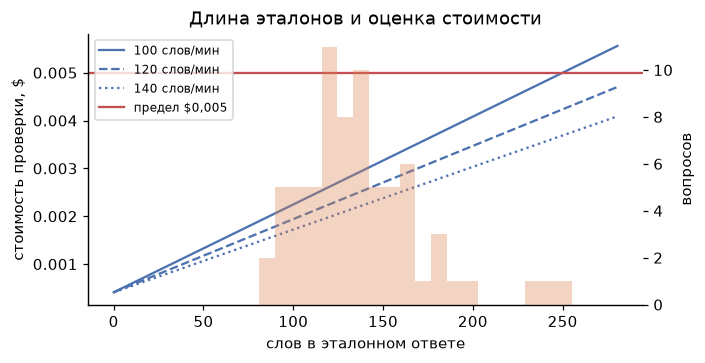

,слов/мин,"медиана, с","медиана, $","максимум, $","доля > $0,005",доля STT
0,100,79.8,0.0029,0.0051,0.0141,0.8562
1,120,66.5,0.0024,0.0043,0.0000,0.8323
2,140,57.0,0.0022,0.0038,0.0000,0.8097


In [10]:
STT_PER_SEC, GRADE_COST, LIMIT = 0.0000306, 0.00041, 0.005
words = pd.Series([len(q.answer.split()) for q in open_qs])

fig, ax = plt.subplots(figsize=(6.5, 3.2))
grid = np.linspace(0, words.max() * 1.1, 200)
for wpm, ls in [(100, "-"), (120, "--"), (140, ":")]:
    ax.plot(grid, grid / wpm * 60 * STT_PER_SEC + GRADE_COST, ls, color="#4c72b0", label=f"{wpm} слов/мин")
ax.axhline(LIMIT, color="#c44e52", label="предел $0,005")
ax2 = ax.twinx()
ax2.hist(words, bins=20, color="#dd8452", alpha=0.35)
ax2.set_ylabel("вопросов")
ax.set_xlabel("слов в эталонном ответе")
ax.set_ylabel("стоимость проверки, $")
ax.set_title("Длина эталонов и оценка стоимости")
ax.legend(loc="upper left", fontsize=8)
plt.show()

rows = []
for wpm in (100, 120, 140):
    sec = words / wpm * 60
    cost = sec * STT_PER_SEC + GRADE_COST
    rows.append(
        (wpm, sec.median(), cost.median(), cost.max(), (cost > LIMIT).mean(), (sec * STT_PER_SEC / cost).median())
    )
cols = ["слов/мин", "медиана, с", "медиана, $", "максимум, $", "доля > $0,005", "доля STT"]
pd.DataFrame(rows, columns=cols).round(4)

**Вывод.** Эталоны — 81–255 слов (медиана 133), то есть устный ответ около минуты. Типичная проверка стоит
\$0,002–0,003, около 80% стоимости — распознавание речи. Предел \$0,005 из бизнес-ограничений достигается только на самых
длинных ответах при медленной речи.

**Ограничение.** Длина эталона — косвенная оценка: живой ответ может быть длиннее за счёт оговорок и пауз. По двум
реальным ответам (24 и 69 с) оценка согласуется, но это слишком мало для вывода.

**Решение.** Стоимость проверки определяется длительностью записи, а не выбором проверяющей модели. Если в пилоте
живые ответы окажутся длиннее, ограничивать длительность записи; при выборе модели проверки запас по цене есть.

## Итог: найденное и решения

| Находка | Влияние на задачу | Решение |
|---|---|---|
| 2 тезиса хранятся как текст словаря | проверяющая модель получает искажённый критерий | исправить; валидатор отклоняет не-строки |
| ~1 из 10 тезисов неоднозначен (треть вопросов) | вердикт «частично» не определён, разметка шумит | переписать до сборки набора; правило в промпт генерации |
| 4–5 тезисов в 93% чек-листов, всего 326 | объём набора: ~430 ответов, ~1 950 решений по тезисам | 6 сценариев на вопрос |
| Группы почти-дубликатов, один явный дубль | утечка между подбором и отложенной частью | делить набор по группам; дубль объединить |
| Проверка стоит ~\$0,002–0,003, ~80% — распознавание | цена зависит от длины записи | следить за длиной живых ответов в пилоте |